## Download the Fish Market dataset

In [4]:
import kagglehub

path = kagglehub.dataset_download("vipullrathod/fish-market")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'fish-market' dataset.
Path to dataset files: /kaggle/input/fish-market


In [5]:
import pandas as pd

## Simple EDA on the dataset

In [6]:
df = pd.read_csv(path + "/Fish.csv")
print(df.head())
print(df.info())
print(df.count())

  Species  Weight  Length1  Length2  Length3   Height   Width
0   Bream   242.0     23.2     25.4     30.0  11.5200  4.0200
1   Bream   290.0     24.0     26.3     31.2  12.4800  4.3056
2   Bream   340.0     23.9     26.5     31.1  12.3778  4.6961
3   Bream   363.0     26.3     29.0     33.5  12.7300  4.4555
4   Bream   430.0     26.5     29.0     34.0  12.4440  5.1340
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159 entries, 0 to 158
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Species  159 non-null    object 
 1   Weight   159 non-null    float64
 2   Length1  159 non-null    float64
 3   Length2  159 non-null    float64
 4   Length3  159 non-null    float64
 5   Height   159 non-null    float64
 6   Width    159 non-null    float64
dtypes: float64(6), object(1)
memory usage: 8.8+ KB
None
Species    159
Weight     159
Length1    159
Length2    159
Length3    159
Height     159
Width      159
dtype: int64


# Check if there are enough samples per Species group in order to apply Linear mixed effect model

In [7]:
df.groupby('Species').size()

,0
Species,
Bream,35
Parkki,11
Perch,56
Pike,17
Roach,20
Smelt,14
Whitefish,6


# Let's compare Linear Mixed Effect (LME) model with a simple linear regression model. The random effect will be the Species groups.

In [8]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

formula = "Weight ~ Length1 + Length2 + Length3 + Height + Width"

model = smf.mixedlm(formula, df, groups=df["Species"])
result = model.fit()

print(result.summary())

           Mixed Linear Model Regression Results
Model:              MixedLM  Dependent Variable:  Weight   
No. Observations:   159      Method:              REML     
No. Groups:         7        Scale:               8803.7751
Min. group size:    6        Log-Likelihood:      -937.5912
Max. group size:    56       Converged:           Yes      
Mean group size:    22.7                                   
-----------------------------------------------------------
            Coef.   Std.Err.   z    P>|z|  [0.025   0.975] 
-----------------------------------------------------------
Intercept  -784.996   88.856 -8.835 0.000 -959.150 -610.843
Length1     -73.539   36.292 -2.026 0.043 -144.669   -2.409
Length2      82.059   44.731  1.834 0.067   -5.613  169.730
Length3      22.726   28.244  0.805 0.421  -32.631   78.083
Height        7.160   12.149  0.589 0.556  -16.652   30.972
Width         4.543   23.369  0.194 0.846  -41.259   50.345
Group Var 35425.423  241.189                       

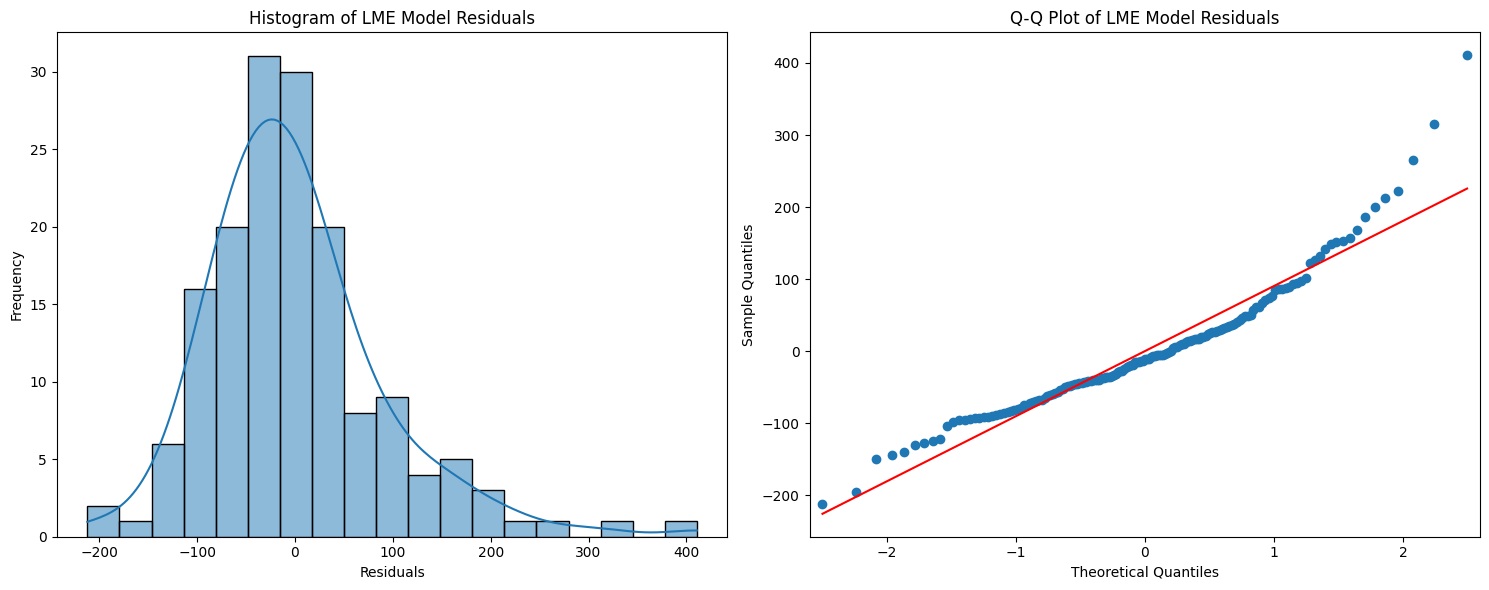

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

def plot_res(residuals, plot_name="LME"):
  fig, axes = plt.subplots(1, 2, figsize=(15, 6))

  sns.histplot(residuals, kde=True, ax=axes[0])
  axes[0].set_title(f"Histogram of {plot_name} Model Residuals")
  axes[0].set_xlabel('Residuals')
  axes[0].set_ylabel('Frequency')

  sm.qqplot(residuals, line='s', ax=axes[1])
  axes[1].set_title(f"Q-Q Plot of {plot_name} Model Residuals")

  plt.tight_layout()
  plt.show()

plot_res(result.resid)

Linear regression model

In [9]:
import statsmodels.api as sm

formula_ols = "Weight ~ Length1 + Length2 + Length3 + Height + Width"

model_ols = sm.formula.ols(formula_ols, data=df).fit()

print(model_ols.summary())


                            OLS Regression Results                            
Dep. Variable:                 Weight   R-squared:                       0.885
Model:                            OLS   Adj. R-squared:                  0.882
Method:                 Least Squares   F-statistic:                     236.2
Date:                Wed, 25 Mar 2026   Prob (F-statistic):           4.95e-70
Time:                        12:21:21   Log-Likelihood:                -987.96
No. Observations:                 159   AIC:                             1988.
Df Residuals:                     153   BIC:                             2006.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   -499.5870     29.572    -16.894      0.0

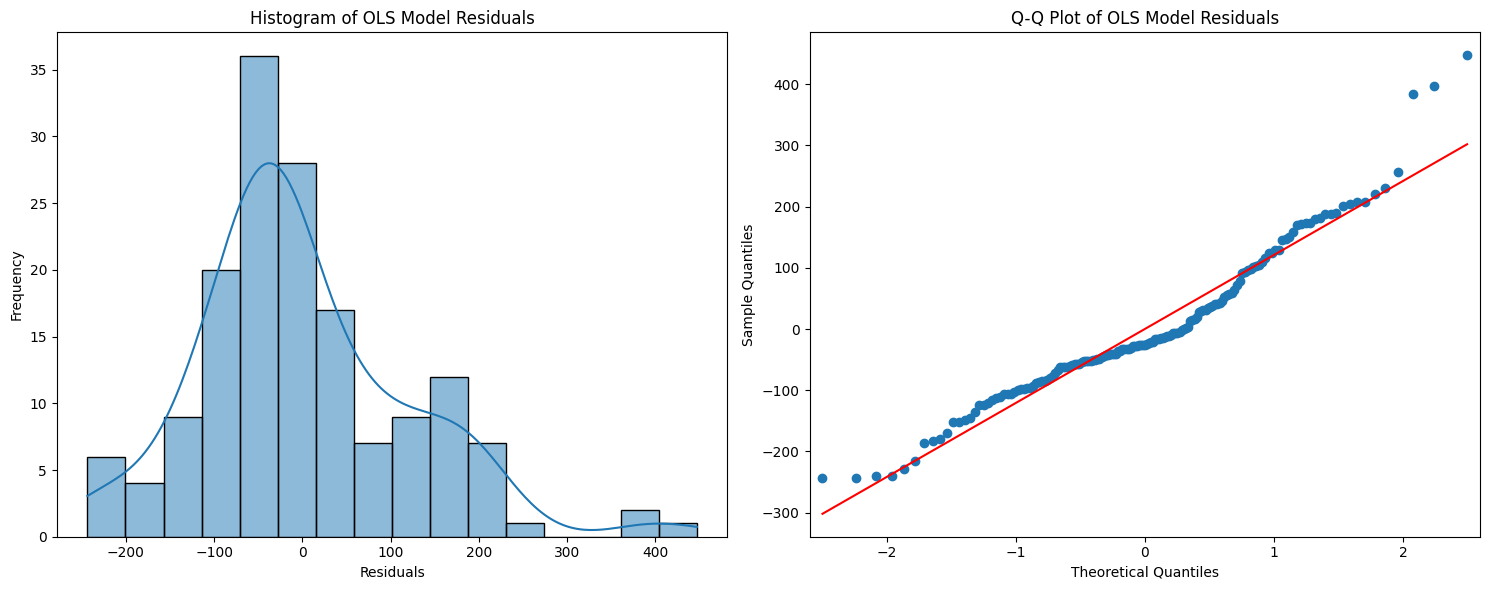

In [13]:
plot_res(model_ols.resid, plot_name="OLS")

The LME model had a Log-Likelihood of -937 , which is higher than the OLS model's -987, suggesting a better fit, especially when comparing models with different structures on the same data. This indicates that accounting for the Species random effect improves the overall fit.

When comparing the residuals distributions, it looks like that the LME's residuals are slightly more normally distributed than the OLS ones.